# FinSight AI - Notebook 4: Independent Evaluation + LLM-as-a-Judge

**Goal:** Evaluate **Base Mistral-7B-v0.3 → Checkpoint 1 DAPT → Checkpoint 2 SFT → Checkpoint 3 DPO** on independent financial QA data.

Evaluation sets:
- FinQA
- ConvFinQA
- TAT-QA
- FiQA
- 50 custom held-out FinSight questions

The notebook evaluates each saved checkpoint independently as **Base + that checkpoint's adapter snapshot**. It also adds a small **LLM-as-a-Judge** evaluation to complement exact-match and numeric metrics with semantic assessment.

In [1]:
!pip -q install -U unsloth transformers datasets accelerate peft bitsandbytes sentencepiece huggingface_hub


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.1/81.1 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.4/25.4 MB 79.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 115.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 41.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 35.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 55.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 44.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.7/119.7 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.3/199.3 kB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
import gc, json, os, random, re, time, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from datasets import load_dataset
from huggingface_hub import hf_hub_download

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
assert torch.cuda.is_available(), "Enable a GPU runtime in Colab."
print("GPU:", torch.cuda.get_device_name(0)); print("CUDA:", torch.version.cuda); print("PyTorch:", torch.__version__)


GPU: Tesla T4
CUDA: 12.8
PyTorch: 2.11.0+cu128


In [3]:
!unzip FinSight_dapt_Checkpoint_1.zip
!unzip FinSight_post_training

Archive:  FinSight_dapt_Checkpoint_1.zip
   creating: FinSight_dapt_Checkpoint_1/
  inflating: FinSight_dapt_Checkpoint_1/checkpoint_1_manifest.json  
   creating: FinSight_dapt_Checkpoint_1/models/
   creating: FinSight_dapt_Checkpoint_1/models/mistral_7b/
   creating: FinSight_dapt_Checkpoint_1/models/mistral_7b/checkpoint_1_adapter/
  inflating: FinSight_dapt_Checkpoint_1/models/mistral_7b/checkpoint_1_adapter/adapter_config.json  
  inflating: FinSight_dapt_Checkpoint_1/models/mistral_7b/checkpoint_1_adapter/adapter_model.safetensors  
  inflating: FinSight_dapt_Checkpoint_1/models/mistral_7b/checkpoint_1_adapter/README.md  
  inflating: FinSight_dapt_Checkpoint_1/models/mistral_7b/checkpoint_1_adapter/tokenizer.json  
  inflating: FinSight_dapt_Checkpoint_1/models/mistral_7b/checkpoint_1_adapter/tokenizer.model  
  inflating: FinSight_dapt_Checkpoint_1/models/mistral_7b/checkpoint_1_adapter/tokenizer_config.json  
  inflating: FinSight_dapt_Checkpoint_1/models/mistral_7b/dapt_resu

## 1. Paths and evaluation controls

Run immediately after Notebook 3 when possible. For a fresh runtime, upload the DAPT and post-training checkpoint directories and the evaluation ZIP.


In [4]:
POST_TRAIN_DIR=Path("/content/FinSight_post_training")
DAPT_DIR=Path("/content/FinSight_dapt_Checkpoint_1")
CUSTOM_EVAL_ROOT=Path("/content/FinSight_evaluation_dataset")
RESULTS_DIR=Path("/content/FinSight_evaluation_results"); RESULTS_DIR.mkdir(parents=True,exist_ok=True)

CHECKPOINT_1_MANIFEST=DAPT_DIR/"checkpoint_1_manifest.json"
CHECKPOINT_2_MANIFEST=POST_TRAIN_DIR/"checkpoint_2_manifest.json"
CHECKPOINT_3_MANIFEST=POST_TRAIN_DIR/"checkpoint_3_manifest.json"

RUN_FULL_BENCHMARKS=False
MAX_PER_BENCHMARK=20
CUSTOM_EVAL_FULL=True
MAX_NEW_TOKENS=128
TEMPERATURE=0.0
DO_SAMPLE=False

print(CHECKPOINT_1_MANIFEST); print(CHECKPOINT_2_MANIFEST); print(CHECKPOINT_3_MANIFEST)


/content/FinSight_dapt_Checkpoint_1/checkpoint_1_manifest.json
/content/FinSight_post_training/checkpoint_2_manifest.json
/content/FinSight_post_training/checkpoint_3_manifest.json


## 2. Load checkpoint manifests and verify the training chain

Notebook 3 trained the stages sequentially: **Base → Checkpoint 1 (DAPT) → Checkpoint 2 (SFT) → Checkpoint 3 (DPO)**. The evaluation therefore composes the adapters sequentially rather than loading Checkpoint 2 or 3 directly on the raw base model.

This is important because PEFT adapter directories can contain only the LoRA delta for the stage that was trained. The manifest parent chain is treated as the source of truth for composition.


In [5]:
def load_json(path):
    path=Path(path)
    if not path.exists(): raise FileNotFoundError(path)
    return json.loads(path.read_text())

checkpoint_1=load_json(CHECKPOINT_1_MANIFEST)
checkpoint_2=load_json(CHECKPOINT_2_MANIFEST)
checkpoint_3=load_json(CHECKPOINT_3_MANIFEST)
BASE_MODEL=checkpoint_1["base_model"]
CHECKPOINT_1_ADAPTER=Path(checkpoint_1["adapter_path"])
CHECKPOINT_2_ADAPTER=Path(checkpoint_2["adapter_path"])
CHECKPOINT_3_ADAPTER=Path(checkpoint_3["adapter_path"])

print("Base:",BASE_MODEL)
print("C1:",CHECKPOINT_1_ADAPTER)
print("C2:",CHECKPOINT_2_ADAPTER)
print("C3:",CHECKPOINT_3_ADAPTER)
for p in [CHECKPOINT_1_ADAPTER,CHECKPOINT_2_ADAPTER,CHECKPOINT_3_ADAPTER]: assert p.exists(), p

# Inspect parent metadata and adapter configs before evaluation.
def adapter_config(path):
    cfg=Path(path)/"adapter_config.json"
    return json.loads(cfg.read_text()) if cfg.exists() else {}

for name,manifest,adapter in [("Checkpoint 1",checkpoint_1,CHECKPOINT_1_ADAPTER),("Checkpoint 2",checkpoint_2,CHECKPOINT_2_ADAPTER),("Checkpoint 3",checkpoint_3,CHECKPOINT_3_ADAPTER)]:
    cfg=adapter_config(adapter)
    print(f"\n{name}")
    print("  manifest stage:",manifest.get("stage"))
    print("  parent checkpoint:",manifest.get("parent_checkpoint"))
    print("  parent adapter:",manifest.get("parent_adapter"))
    print("  adapter base_model_name_or_path:",cfg.get("base_model_name_or_path"))
    print("  r:",cfg.get("r"), "alpha:",cfg.get("lora_alpha"))


Base: mistralai/Mistral-7B-v0.3
C1: /content/FinSight_dapt_Checkpoint_1/models/mistral_7b/checkpoint_1_adapter
C2: /content/FinSight_post_training/checkpoint_2_sft_adapter
C3: /content/FinSight_post_training/checkpoint_3_dpo_adapter

Checkpoint 1
  manifest stage: None
  parent checkpoint: None
  parent adapter: None
  adapter base_model_name_or_path: unsloth/mistral-7b-v0.3-bnb-4bit
  r: 16 alpha: 16

Checkpoint 2
  manifest stage: supervised_fine_tuning
  parent checkpoint: checkpoint_1
  parent adapter: /content/FinSight_dapt_Checkpoint_1/models/mistral_7b/checkpoint_1_adapter
  adapter base_model_name_or_path: unsloth/mistral-7b-v0.3-bnb-4bit
  r: 16 alpha: 16

Checkpoint 3
  manifest stage: direct_preference_optimization
  parent checkpoint: checkpoint_2
  parent adapter: /content/FinSight_post_training/checkpoint_2_sft_adapter
  adapter base_model_name_or_path: unsloth/mistral-7b-v0.3-bnb-4bit
  r: 16 alpha: 16


### Why the adapter audit matters

The earlier evaluation loaded each adapter directly onto the raw base model. That can evaluate C2/C3 incorrectly if their saved directories contain only the stage-specific LoRA delta. The revised notebook explicitly reconstructs the training chain before scoring.


## 3. Load public evaluation datasets

FinQA uses its test split. ConvFinQA uses its dev split because the public labeled release exposes dev answers. TAT-QA uses the public dev JSON. FiQA uses its available test split, falling back to validation.


In [6]:
finqa=load_dataset("bevaya/FinQA",split="test")
if not RUN_FULL_BENCHMARKS: finqa=finqa.shuffle(seed=SEED).select(range(min(MAX_PER_BENCHMARK,len(finqa))))
print("FinQA:",len(finqa),finqa.column_names)

conv_path=hf_hub_download(repo_id="sharick008/convfinqa",filename="convfinqa_dataset.json",repo_type="dataset")
conv_data=json.loads(Path(conv_path).read_text())
conv_records=conv_data["dev"]
if not RUN_FULL_BENCHMARKS:
    rng=random.Random(SEED); idx=list(range(len(conv_records))); rng.shuffle(idx); conv_records=[conv_records[i] for i in idx[:min(MAX_PER_BENCHMARK,len(idx))]]
print("ConvFinQA:",len(conv_records))

tat_path=hf_hub_download(repo_id="TableQAKit/TAT-QA",filename="tatqa_dataset_dev.json",repo_type="dataset")
tat_records=json.loads(Path(tat_path).read_text())
if not RUN_FULL_BENCHMARKS:
    rng=random.Random(SEED); idx=list(range(len(tat_records))); rng.shuffle(idx); tat_records=[tat_records[i] for i in idx[:min(MAX_PER_BENCHMARK,len(idx))]]
print("TAT-QA:",len(tat_records))

fiqa=load_dataset("LLukas22/fiqa")
fiqa_split=fiqa["test"] if "test" in fiqa else fiqa["validation"] if "validation" in fiqa else fiqa[list(fiqa.keys())[0]]
if not RUN_FULL_BENCHMARKS: fiqa_split=fiqa_split.shuffle(seed=SEED).select(range(min(MAX_PER_BENCHMARK,len(fiqa_split))))
print("FiQA:",len(fiqa_split))


README.md:   0%|          | 0.00/6.39k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 30.1MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 4.20MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

train.json: downloading bytes:           |  0.00B            

test.json:   0%|          | 0.00/2.82M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/14511 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2561 [00:00<?, ? examples/s]

FiQA: 20


In [7]:
def s(x): return "" if x is None else str(x)
def join_text(x): return "\n".join(map(str,x)) if isinstance(x,list) else s(x)
def format_table(t):
    if t is None: return ""
    if isinstance(t,dict):
        out=[]
        for k,v in t.items():
            if isinstance(v,dict): out.append(" | ".join([str(k)]+[f"{a}: {b}" for a,b in v.items()]))
            else: out.append(f"{k} | {v}")
        return "\n".join(out)
    if isinstance(t,list): return "\n".join(" | ".join(map(str,r)) if isinstance(r,(list,tuple)) else str(r) for r in t)
    return str(t)

def norm_finqa(r):
    return {"dataset":"FinQA","id":s(r.get("id")),"context":"PRE-TEXT:\n"+join_text(r.get("pre_text"))+"\n\nTABLE:\n"+format_table(r.get("table"))+"\n\nPOST-TEXT:\n"+join_text(r.get("post_text")),"question":s(r.get("question")),"reference_answer":s(r.get("answer")),"task_type":"financial_numerical_reasoning"}

def norm_conv(r):
    d=r.get("doc",{}); qd=r.get("dialogue",{}); qs=qd.get("conv_questions",[]); ans=qd.get("conv_answers",[]); ex=qd.get("executed_answers",[])
    if not qs: return None
    hist=[]
    for i in range(len(qs)-1): hist.append(f"Previous question {i+1}: {qs[i]}\nPrevious answer {i+1}: {ans[i] if i<len(ans) else ''}")
    return {"dataset":"ConvFinQA","id":s(r.get("id")),"context":"PRE-TEXT:\n"+join_text(d.get("pre_text"))+"\n\nTABLE:\n"+format_table(d.get("table"))+"\n\nPOST-TEXT:\n"+join_text(d.get("post_text"))+"\n\nCONVERSATION HISTORY:\n"+"\n".join(hist),"question":s(qs[-1]),"reference_answer":s(ex[-1] if ex else (ans[-1] if ans else "")),"task_type":"conversational_financial_reasoning"}

def norm_tat(r):
    qa=r.get("qa",r); return {"dataset":"TAT-QA","id":s(r.get("id",qa.get("id"))),"context":"PARAGRAPHS:\n"+join_text(r.get("paragraphs",r.get("pre_text",[])))+"\n\nTABLE:\n"+format_table(r.get("table",r.get("table_ori",[]))),"question":s(qa.get("question",r.get("question"))),"reference_answer":s(qa.get("answer",r.get("answer"))),"task_type":"table_text_financial_qa"}

def norm_fiqa(r): return {"dataset":"FiQA","id":s(r.get("id")),"context":"","question":s(r.get("question")),"reference_answer":s(r.get("answer")),"task_type":"financial_qa"}

records=[norm_finqa(r) for r in finqa]
records += [x for x in (norm_conv(r) for r in conv_records) if x]
records += [norm_tat(r) for r in tat_records]
records += [norm_fiqa(r) for r in fiqa_split]
benchmark_df=pd.DataFrame(records)
print(benchmark_df["dataset"].value_counts())


dataset
FinQA        20
ConvFinQA    20
TAT-QA       20
FiQA         20
Name: count, dtype: int64


## 4. Load the 50 custom held-out questions


In [8]:
matches=list(CUSTOM_EVAL_ROOT.rglob("custom_financial_eval_50.jsonl"))
if not matches: raise FileNotFoundError("custom_financial_eval_50.jsonl not found. Upload FinSight_evaluation_dataset.zip.")
custom_records=[json.loads(x) for x in matches[0].read_text().splitlines() if x.strip()]
if CUSTOM_EVAL_FULL: chosen=custom_records
else:
    rng=random.Random(SEED); idx=list(range(len(custom_records))); rng.shuffle(idx); chosen=[custom_records[i] for i in idx[:MAX_PER_BENCHMARK]]

def norm_custom(r): return {"dataset":"Custom-50","id":s(r.get("id")),"context":s(r.get("context",r.get("evidence",""))),"question":s(r.get("question",r.get("instruction",""))),"reference_answer":s(r.get("answer",r.get("reference_answer",r.get("gold_answer","")))),"task_type":s(r.get("category","custom_financial_evaluation"))}
custom_df=pd.DataFrame([norm_custom(r) for r in chosen])
print("Custom:",len(custom_df)); print(custom_df["task_type"].value_counts())
all_eval_df=pd.concat([benchmark_df,custom_df],ignore_index=True)
print("Total evaluation questions:",len(all_eval_df))


Custom: 50
task_type
custom_financial_evaluation    50
Name: count, dtype: int64
Total evaluation questions: 130


## 5. Common FinSight prompt and model loading


In [9]:
from unsloth import FastLanguageModel
from peft import PeftModel
from unsloth.chat_templates import get_chat_template

def load_base_and_tokenizer():
    """Load the raw base model and the Mistral chat template."""
    base, tokenizer = FastLanguageModel.from_pretrained(
        model_name=BASE_MODEL,
        max_seq_length=1024,
        dtype=None,
        load_in_4bit=True,
    )
    tokenizer = get_chat_template(tokenizer, chat_template="mistral")
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "left"
    return base, tokenizer

def load_adapter_into(model, adapter_path):
    """Attach one saved adapter snapshot to the raw base model."""
    return PeftModel.from_pretrained(
        model,
        str(adapter_path),
        is_trainable=False,
    )

def compose_stage(stage):
    """
    Evaluate each saved checkpoint independently.

    C1 = Base + C1 adapter
    C2 = Base + C2 adapter snapshot
    C3 = Base + C3 adapter snapshot

    C2 and C3 are successive snapshots from Notebook 3, not adapters
    that should be stacked during evaluation.
    """
    base, tokenizer = load_base_and_tokenizer()

    if stage == "Base":
        return base, tokenizer

    adapter_map = {
        "Checkpoint 1": CHECKPOINT_1_ADAPTER,
        "Checkpoint 2": CHECKPOINT_2_ADAPTER,
        "Checkpoint 3": CHECKPOINT_3_ADAPTER,
    }

    if stage not in adapter_map:
        raise ValueError(f"Unknown stage: {stage}")

    return load_adapter_into(base, adapter_map[stage]), tokenizer

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


In [10]:
def build_inputs(stage, tokenizer, context, question):
    """Build the same Mistral chat-style prompt for every evaluation stage."""
    system_message = (
        "You are FinSight AI, a financial analyst assistant. "
        "Answer using only the provided financial context. "
        "Perform calculations carefully when required. "
        "Give a concise, grounded answer and do not invent information."
    )

    user_message = f"""Financial Context:
{context}

Question:
{question}

Answer:"""

    messages = [
        {"role": "system", "content": system_message},
        {"role": "user", "content": user_message},
    ]

    return tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        return_dict=True,
    )

@torch.inference_mode()
def generate_answer(stage, model, tokenizer, context, question):
    inputs = build_inputs(stage, tokenizer, context, question)
    inputs = {k: v.to(model.device) for k, v in inputs.items()}

    if getattr(model, "generation_config", None) is not None:
        model.generation_config.max_length = None

    kwargs = dict(
        max_new_tokens=MAX_NEW_TOKENS,
        do_sample=DO_SAMPLE,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )
    if DO_SAMPLE:
        kwargs["temperature"] = TEMPERATURE

    output = model.generate(**inputs, **kwargs)
    generated_tokens = output[0][inputs["input_ids"].shape[1]:]

    return tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True,
    ).strip()

In [11]:
def normalize_text(x):
    x = s(x).lower().strip().replace(",", "")
    x = re.sub(r"[$€£₹]", "", x)
    x = re.sub(r"\s+", " ", x)
    x = re.sub(r"[^a-z0-9.%+\- ]", "", x)
    return x.strip()

def token_f1(pred, ref):
    p, r = normalize_text(pred).split(), normalize_text(ref).split()
    if not p or not r:
        return float(p == r)

    pc, rc = {}, {}
    for t in p: pc[t] = pc.get(t, 0) + 1
    for t in r: rc[t] = rc.get(t, 0) + 1

    common = sum(min(pc.get(t, 0), c) for t, c in rc.items())
    if common == 0:
        return 0.0

    precision = common / len(p)
    recall = common / len(r)
    return 2 * precision * recall / (precision + recall)

def nums(x):
    values = []
    text = s(x).replace(",", "")
    for m in re.findall(r"[-+]?\d+(?:\.\d+)?(?:%|[kKmMbB])?", text):
        raw = m.rstrip("%kKmMbB")
        try:
            value = float(raw)
            if "%" in m:
                value /= 100
            elif m[-1].lower() == "k":
                value *= 1e3
            elif m[-1].lower() == "m":
                value *= 1e6
            elif m[-1].lower() == "b":
                value *= 1e9
            values.append(value)
        except Exception:
            pass
    return values

def numeric_match(pred, ref, tol=0.02):
    pn, rn = nums(pred), nums(ref)
    if not pn or not rn:
        return 0
    for p in pn:
        for r in rn:
            if abs(p - r) <= tol * max(1.0, abs(r)):
                return 1
    return 0

def reference_in_prediction(pred, ref):
    p, r = normalize_text(pred), normalize_text(ref)
    return int(bool(r) and r in p)

def binary_answer_match(pred, ref):
    p, r = normalize_text(pred), normalize_text(ref)
    if r not in {"yes", "no"}:
        return np.nan
    first = re.search(r"\b(yes|no)\b", p)
    return int(first.group(1) == r) if first else 0

def metrics(pred, ref):
    return {
        "exact_match": int(normalize_text(pred) == normalize_text(ref)),
        "token_f1": token_f1(pred, ref),
        "numeric_accuracy": numeric_match(pred, ref),
        "reference_in_prediction": reference_in_prediction(pred, ref),
        "binary_answer_match": binary_answer_match(pred, ref),
    }

## 6. Checkpoint sanity test

Each checkpoint is loaded independently and tested on two simple financial questions before the full benchmark is run.

This is a diagnostic gate for empty output, token corruption, or decoding failures. It is not a quality score.

In [12]:

STAGES=["Base","Checkpoint 1","Checkpoint 2","Checkpoint 3"]
SANITY_QUESTIONS = [
    {
        "context": (
            "Revenue increased from $100 million in 2023 to $120 million in 2024. "
            "Operating expenses increased from $60 million to $66 million."
        ),
        "question": "What was the percentage increase in revenue from 2023 to 2024?",
    },
    {
        "context": (
            "A company reported total assets of $500 million and total liabilities of "
            "$320 million at year-end."
        ),
        "question": "What was the company's equity at year-end?",
    },
]

def sanity_check_stage(stage):
    model, tokenizer = compose_stage(stage)
    outputs = []
    try:
        for item in SANITY_QUESTIONS:
            pred = generate_answer(
                stage,
                model,
                tokenizer,
                item["context"],
                item["question"],
            )
            outputs.append(pred)
    finally:
        del model, tokenizer
        gc.collect()
        torch.cuda.empty_cache()

    print("\n" + "=" * 80)
    print(stage)
    print("=" * 80)
    for i, pred in enumerate(outputs, 1):
        print(f"\nQuestion {i}: {SANITY_QUESTIONS[i-1]['question']}")
        print("Prediction:", pred[:500] if pred else "<EMPTY>")

    healthy = True
    for pred in outputs:
        if not pred.strip():
            healthy = False
        if len(pred.strip()) < 2:
            healthy = False
        # Very rough corruption guard. This is diagnostic, not a quality score.
        weird_ratio = sum(
            1 for ch in pred
            if not (ch.isalnum() or ch.isspace() or ch in ".,%$+-:/()'\"")
        ) / max(1, len(pred))
        if weird_ratio > 0.35:
            healthy = False

    return healthy, outputs

sanity_status = {}
for stage in STAGES:
    ok, _ = sanity_check_stage(stage)
    sanity_status[stage] = ok

print("\nSanity-test status:")
for stage, ok in sanity_status.items():
    print(f"{stage:15s}: {'PASS' if ok else 'FAIL'}")

if not all(sanity_status.values()):
    failed = [stage for stage, ok in sanity_status.items() if not ok]
    raise RuntimeError(
        "Checkpoint sanity test failed for: "
        + ", ".join(failed)
        + ". Do not run the full evaluation until the checkpoint loading/generation issue is resolved."
    )

print("\nAll four stages passed the basic generation sanity check.")


==((====))==  Unsloth 2026.9.12: Fast Mistral patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]


Base

Question 1: What was the percentage increase in revenue from 2023 to 2024?
Prediction: Explanation:
The percentage increase in revenue from 2023 to 2024 can be calculated using the following formula:

Percentage increase = (New value – Old value) / Old value * 100

In this case, the new value is $120 million, and the old value is $100 million. Therefore, the percentage increase in revenue is:

(120 – 100) / 100 * 100 = 20%

Therefore, the percentage increase in revenue from

Question 2: What was the company's equity at year-end?
Prediction: FinSight AI is a financial analyst assistant that can help you with your financial analysis. It can answer questions about financial statements, perform calculations, and give concise, grounded answers.

To use FinSight AI, you need to provide it with financial context. This can be in the form of financial statements, financial reports, or other financial information.

FinSight AI can answer questions about financial statements, such as what 

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]


Checkpoint 1

Question 1: What was the percentage increase in revenue from 2023 to 2024?
Prediction: Explanation:
The percentage increase in revenue from 2023 to 2024 can be calculated using the following formula:

% increase = (new value – old value) / old value * 100

In this case, the new value is $120 million, and the old value is $100 million. Therefore, the percentage increase in revenue is:

% increase = (120 – 100) / 100 * 100 = 20%

Therefore, the answer to the question

Question 2: What was the company's equity at year-end?
Prediction: Explanation:
The company's equity at year-end is calculated as the difference between total assets and total liabilities.

Total assets = $500 million
Total liabilities = $320 million
Equity = $500 million - $320 million = $180 million

Therefore, the company's equity at year-end is $180 million.
==((====))==  Unsloth 2026.9.12: Fast Mistral patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: L

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]


Checkpoint 2

Question 1: What was the percentage increase in revenue from 2023 to 2024?
Prediction: The revenue increased from $100 million to $120 million, a 20% increase.

Question 2: What was the company's equity at year-end?
Prediction: Equity = total assets - total liabilities. Equity = $500M - $320M = $180M.
==((====))==  Unsloth 2026.9.12: Fast Mistral patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]


Checkpoint 3

Question 1: What was the percentage increase in revenue from 2023 to 2024?
Prediction: Revenue increased from $100 million in 2023 to $120 million in 2024, a 20% growth rate.

Question 2: What was the company's equity at year-end?
Prediction: Equity = total assets - total liabilities. Equity = $500M - $320M = $180M.

Sanity-test status:
Base           : PASS
Checkpoint 1   : PASS
Checkpoint 2   : PASS
Checkpoint 3   : PASS

All four stages passed the basic generation sanity check.


## 7. Run the four-stage evaluation


In [13]:
STAGES = ["Base", "Checkpoint 1", "Checkpoint 2", "Checkpoint 3"]

def evaluate_stage(stage, df):
    print("\n" + "=" * 70)
    print("Evaluating", stage)
    print("=" * 70)

    model, tokenizer = compose_stage(stage)
    rows, start = [], time.time()

    try:
        for _, r in tqdm(df.iterrows(), total=len(df), desc=stage):
            try:
                pred = generate_answer(
                    stage, model, tokenizer, r["context"], r["question"]
                )
                m = metrics(pred, r["reference_answer"])

                rows.append({
                    **{k: r[k] for k in [
                        "dataset", "id", "task_type",
                        "question", "reference_answer"
                    ]},
                    "prediction": pred,
                    **m,
                    "status": "ok",
                    "prompt_mode": "mistral_chat_template",
                })
            except Exception as e:
                rows.append({
                    **{k: r[k] for k in [
                        "dataset", "id", "task_type",
                        "question", "reference_answer"
                    ]},
                    "prediction": "",
                    "exact_match": 0,
                    "token_f1": 0.0,
                    "numeric_accuracy": 0,
                    "reference_in_prediction": 0,
                    "binary_answer_match": np.nan,
                    "status": f"error: {type(e).__name__}: {e}",
                    "prompt_mode": "mistral_chat_template",
                })
    finally:
        elapsed = time.time() - start
        del model, tokenizer
        gc.collect()
        torch.cuda.empty_cache()

    result = pd.DataFrame(rows)
    result["stage"] = stage
    result.to_csv(
        RESULTS_DIR / f"{stage.lower().replace(' ', '_')}_predictions.csv",
        index=False
    )

    print(f"{stage} complete: {len(result)} rows in {elapsed/60:.2f} minutes")
    return result

stage_frames = [evaluate_stage(stage, all_eval_df) for stage in STAGES]
combined_df = pd.concat(stage_frames, ignore_index=True)

print("Combined evaluation rows:", len(combined_df))
display(combined_df.head())


Evaluating Base
==((====))==  Unsloth 2026.9.12: Fast Mistral patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Base:   0%|          | 0/130 [00:00<?, ?it/s]

Unsloth: Input IDs of shape torch.Size([1, 1152]) with length 1152 > the model's max sequence length of 1024.
We shall truncate it ourselves. It's imperative if you correct this issue first.
Unsloth: Input IDs of shape torch.Size([1, 1173]) with length 1173 > the model's max sequence length of 1024.
We shall truncate it ourselves. It's imperative if you correct this issue first.
Unsloth: Input IDs of shape torch.Size([1, 1257]) with length 1257 > the model's max sequence length of 1024.
We shall truncate it ourselves. It's imperative if you correct this issue first.
Unsloth: Input IDs of shape torch.Size([1, 1538]) with length 1538 > the model's max sequence length of 1024.
We shall truncate it ourselves. It's imperative if you correct this issue first.
Unsloth: Input IDs of shape torch.Size([1, 1068]) with length 1068 > the model's max sequence length of 1024.
We shall truncate it ourselves. It's imperative if you correct this issue first.
Unsloth: Input IDs of shape torch.Size([1, 13

Base complete: 130 rows in 17.36 minutes

Evaluating Checkpoint 1
==((====))==  Unsloth 2026.9.12: Fast Mistral patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


...

Checkpoint 2 complete: 130 rows in 9.18 minutes

Evaluating Checkpoint 3
==((====))==  Unsloth 2026.9.12: Fast Mistral patching. Transformers: 5.5.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

Checkpoint 3:   0%|          | 0/130 [00:00<?, ?it/s]

Checkpoint 3 complete: 130 rows in 8.32 minutes
Combined evaluation rows: 520


,dataset,id,task_type,question,reference_answer,prediction,exact_match,token_f1,numeric_accuracy,reference_in_prediction,binary_answer_match,status,prompt_mode,stage
0,FinQA,GS/2014/page_165.pdf-3,financial_numerical_reasoning,"in millions for 2014 and 2013 , what was the c...",494,| 100 | 100\nother liabilities and accrued exp...,0,0.0,0,0,NaN,ok,mistral_chat_template,Base
1,FinQA,GS/2013/page_220.pdf-1,financial_numerical_reasoning,what is the five year total return on the gold...,148.36,248.36\n\nExplanation:\n\nThe five year total ...,0,0.0,0,0,NaN,ok,mistral_chat_template,Base
2,FinQA,DRE/2012/page_40.pdf-1,financial_numerical_reasoning,what was the percentage reduction second gener...,-46.8%,26643 | $ 50079 | $ 36676\n\nQuestion:\nwhat w...,0,0.0,0,0,NaN,ok,mistral_chat_template,Base
3,FinQA,ABMD/2012/page_41.pdf-1,financial_numerical_reasoning,did abiomed outperform the nasdaq composite in...,yes,Explanation:\n\nThe question asks whether Abio...,0,0.0,0,0,0.0,ok,mistral_chat_template,Base
4,FinQA,AES/2001/page_85.pdf-1,financial_numerical_reasoning,what percentage of scheduled maturities of tot...,12%,"2019s debt , including the revolving bank loan...",0,0.0,0,0,NaN,ok,mistral_chat_template,Base


## 8. Metrics and comparison tables


In [14]:
METRICS = [
    "exact_match",
    "token_f1",
    "numeric_accuracy",
    "reference_in_prediction",
]

overall = (
    combined_df.groupby("stage")[METRICS]
    .mean()
    .reindex(STAGES)
)

summary = (
    combined_df.groupby(["stage", "dataset"])[METRICS]
    .mean()
    .reset_index()
)

print("Overall automated metrics")
display(overall.round(4))

print("\nDataset-level metrics")
for metric in METRICS:
    print("\n" + metric.upper())
    display(
        summary.pivot(
            index="dataset", columns="stage", values=metric
        ).reindex(columns=STAGES).round(4)
    )

custom_summary = (
    combined_df[combined_df.dataset == "Custom-50"]
    .groupby("stage")[METRICS]
    .mean()
    .reindex(STAGES)
)

print("\nCustom 50 held-out results")
display(custom_summary.round(4))

binary_rows = combined_df[
    combined_df.reference_answer.astype(str).str.lower().str.strip().isin(["yes", "no"])
].copy()

if len(binary_rows):
    binary_summary = (
        binary_rows.groupby("stage")["binary_answer_match"]
        .mean().reindex(STAGES)
    )
    print("\nBinary yes/no answer match")
    display(binary_summary.round(4))

print("\nChange from Base")
display(overall.subtract(overall.loc["Base"]).round(4))

Overall automated metrics


,exact_match,token_f1,numeric_accuracy,reference_in_prediction
stage,,,,
Base,0.0385,0.0434,0.0231,0.0000
Checkpoint 1,0.0308,0.0363,0.0308,0.0077
Checkpoint 2,0.0000,0.0324,0.0846,0.0231
Checkpoint 3,0.0000,0.0315,0.0769,0.0231



Dataset-level metrics

EXACT_MATCH


stage,Base,Checkpoint 1,Checkpoint 2,Checkpoint 3
dataset,,,,
ConvFinQA,0.00,0.0,0.0,0.0
Custom-50,0.00,0.0,0.0,0.0
FiQA,0.00,0.0,0.0,0.0
FinQA,0.00,0.0,0.0,0.0
TAT-QA,0.25,0.2,0.0,0.0



TOKEN_F1


...

,exact_match,token_f1,numeric_accuracy,reference_in_prediction
stage,,,,
Base,0.0,0.0006,0.00,0.00
Checkpoint 1,0.0,0.0000,0.00,0.00
Checkpoint 2,0.0,0.0310,0.04,0.04
Checkpoint 3,0.0,0.0248,0.04,0.04



Binary yes/no answer match


,binary_answer_match
stage,
Base,0.0
Checkpoint 1,0.5
Checkpoint 2,1.0
Checkpoint 3,0.5



Change from Base


,exact_match,token_f1,numeric_accuracy,reference_in_prediction
stage,,,,
Base,0.0000,0.0000,0.0000,0.0000
Checkpoint 1,-0.0077,-0.0072,0.0077,0.0077
Checkpoint 2,-0.0385,-0.0110,0.0615,0.0231
Checkpoint 3,-0.0385,-0.0119,0.0538,0.0231


## 9. Small LLM-as-a-Judge evaluation

Automated metrics can be overly strict for explanatory financial answers. This section evaluates a small stratified sample with an external judge LLM.

The judge assesses:
- correctness
- numerical correctness
- grounding
- reasoning quality
- completeness
- hallucination risk
- overall quality

The stage label is not shown to the judge. If `OPENAI_API_KEY` is unavailable, this section is skipped.

In [ ]:
import os
os.environ["OPENAI_API_KEY"] = "sk-proj"

In [38]:
import os

key = os.environ.get("OPENAI_API_KEY")

print("API key exists:", bool(key))
print("Key prefix:", key[:8] + "..." if key else "MISSING")

API key exists: True
Key prefix: sk-proj-...


In [39]:
import os, re, json
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from openai import OpenAI
import openai

JUDGE_ENABLED = True
JUDGE_MODEL = "gpt-4.1-mini"
JUDGE_SAMPLES_PER_STAGE = 8
JUDGE_MAX_CONTEXT_CHARS = 6000
JUDGE_MAX_ANSWER_CHARS = 2500
JUDGE_MAX_REFERENCE_CHARS = 1500

JUDGE_METRICS = [
    "correctness", "numerical_correctness", "grounding",
    "reasoning_quality", "completeness", "hallucination_risk", "overall_score",
]


def attach_context(df, source_df):
    """
    combined_df was built by looping over all_eval_df once per stage, so within each
    stage the rows are in the same order as all_eval_df. Attach context by position
    and verify dataset + question match, so nothing is silently misaligned.
    """
    df = df.copy()
    df["context"] = ""
    src_ds = source_df["dataset"].astype(str).values
    src_q = source_df["question"].astype(str).values
    src_ctx = source_df["context"].fillna("").astype(str).values

    for stage, g in df.groupby("stage", sort=False):
        if len(g) != len(source_df):
            raise ValueError(f"{stage}: {len(g)} rows vs {len(source_df)} in all_eval_df")
        if not (g["dataset"].astype(str).values == src_ds).all():
            raise ValueError(f"{stage}: dataset order differs from all_eval_df")
        if not (g["question"].astype(str).values == src_q).all():
            raise ValueError(f"{stage}: question order differs from all_eval_df")
        df.loc[g.index, "context"] = src_ctx

    return df


def select_judge_sample(df, n=8, seed=42):
    if len(df) <= n:
        return df.copy()

    pieces = []
    for group_no, (_, group) in enumerate(
        df.groupby(["dataset", "task_type"], dropna=False)
    ):
        pieces.append(group.sample(n=1, random_state=seed + group_no))

    sample = pd.concat(pieces) if pieces else df.head(0)
    sample = sample.sample(frac=1, random_state=seed)  # avoid bias toward first groups

    if len(sample) < n:
        remaining = df.drop(index=sample.index, errors="ignore")
        if len(remaining):
            sample = pd.concat([
                sample,
                remaining.sample(n=min(n - len(sample), len(remaining)), random_state=seed),
            ])

    return sample.head(n).copy()


def judge_prompt(row):
    context = s(row["context"])[:JUDGE_MAX_CONTEXT_CHARS]
    if not context.strip():
        context = "(No context provided for this question.)"
    question = s(row["question"])
    reference = s(row["reference_answer"])[:JUDGE_MAX_REFERENCE_CHARS]
    prediction = s(row["prediction"])[:JUDGE_MAX_ANSWER_CHARS]

    return f"""
You are evaluating a financial question-answering model.

Evaluate the MODEL ANSWER against the QUESTION, FINANCIAL CONTEXT, and REFERENCE ANSWER.

Return ONLY valid JSON using exactly this schema:
{{
  "correctness": 0,
  "numerical_correctness": 0,
  "grounding": 0,
  "reasoning_quality": 1,
  "completeness": 1,
  "hallucination_risk": 0,
  "overall_score": 1,
  "short_reason": "brief explanation"
}}

Scales:
- correctness: 0 or 1
- numerical_correctness: 0 or 1
- grounding: 0 or 1
- reasoning_quality: 1 to 5
- completeness: 1 to 5
- hallucination_risk: 0 or 1, where 1 means unsupported content is present
- overall_score: 1 to 5

FINANCIAL CONTEXT:
{context}

QUESTION:
{question}

REFERENCE ANSWER:
{reference}

MODEL ANSWER:
{prediction}
""".strip()


def _extract_json(raw):
    raw = raw.strip()
    raw = re.sub(r"^```(?:json)?\s*", "", raw)
    raw = re.sub(r"\s*```$", "", raw)
    try:
        return json.loads(raw)
    except json.JSONDecodeError:
        m = re.search(r"\{.*\}", raw, flags=re.DOTALL)
        if m:
            return json.loads(m.group(0))
        raise


def run_llm_judge(judge_df, source_df):
    if not JUDGE_ENABLED:
        print("LLM judge disabled.")
        return pd.DataFrame()

    api_key = os.environ.get("OPENAI_API_KEY")
    if not api_key:
        raise RuntimeError("OPENAI_API_KEY not found in os.environ.")

    judge_df = attach_context(judge_df, source_df)

    # Only judge rows that can actually be judged
    ok_rows = (
        judge_df["question"].astype(str).str.strip().ne("")
        & judge_df["reference_answer"].astype(str).str.strip().ne("")
        & judge_df["status"].eq("ok")
    )
    skipped = (~ok_rows).sum()
    if skipped:
        print(f"Skipping {skipped} rows with empty question/reference or generation error:")
        print(judge_df.loc[~ok_rows].groupby(["stage", "dataset"]).size())
    judge_df = judge_df[ok_rows].copy()

    print("Rows with context:", (judge_df["context"].str.strip() != "").groupby(judge_df["dataset"]).mean().round(2).to_dict())

    client = OpenAI(api_key=api_key)
    print(f"openai SDK {openai.__version__}")

    def call_judge(prompt):
        resp = client.responses.create(model=JUDGE_MODEL, input=prompt)
        return resp.output_text

    # Smoke test on a real row: fails loudly instead of producing NaN rows
    _extract_json(call_judge(judge_prompt(judge_df.iloc[0])))
    print("Smoke test on first row: OK")

    rows, first_error_printed = [], False

    for stage in STAGES:
        stage_df = judge_df[judge_df.stage == stage]
        if stage_df.empty:
            continue
        sample = select_judge_sample(stage_df, n=JUDGE_SAMPLES_PER_STAGE, seed=SEED)

        for _, row in tqdm(sample.iterrows(), total=len(sample), desc=f"Judge: {stage}"):
            base = {
                "stage": stage,
                "dataset": row["dataset"],
                "id": row["id"],
                "question": row["question"],
                "prediction": row["prediction"],
                "reference_answer": row["reference_answer"],
                "judge_model": JUDGE_MODEL,
            }
            try:
                score = _extract_json(call_judge(judge_prompt(row)))
                rows.append({**base, **score, "judge_status": "ok"})
            except Exception as e:
                if not first_error_printed:
                    print(f"First judge error: {type(e).__name__}: {e}")
                    first_error_printed = True
                rows.append({
                    **base,
                    **{k: np.nan for k in JUDGE_METRICS},
                    "short_reason": "",
                    "judge_status": f"error: {type(e).__name__}: {e}",
                })

    result = pd.DataFrame(rows)
    if len(result):
        result.to_csv(RESULTS_DIR / "llm_judge_results.csv", index=False)
        print("Judge status counts:")
        print(result["judge_status"].str.slice(0, 80).value_counts())
    return result


judge_results = run_llm_judge(combined_df, all_eval_df)

if len(judge_results):
    judge_metrics = [m for m in JUDGE_METRICS if m in judge_results.columns]
    judge_summary = (
        judge_results.groupby("stage")[judge_metrics].mean().reindex(STAGES)
    )
    print("LLM-as-a-Judge summary")
    display(judge_summary.round(3))
    display(
        judge_results[
            ["stage", "dataset", "id", "overall_score", "correctness",
             "numerical_correctness", "grounding", "reasoning_quality",
             "completeness", "hallucination_risk", "short_reason", "judge_status"]
        ].head(20)
    )
else:
    judge_summary = pd.DataFrame()
    print("No judge results produced.")

Skipping 80 rows with empty question/reference or generation error:
stage         dataset
Base          TAT-QA     20
Checkpoint 1  TAT-QA     20
Checkpoint 2  TAT-QA     20
Checkpoint 3  TAT-QA     20
dtype: int64
Rows with context: {'ConvFinQA': 1.0, 'Custom-50': 0.0, 'FiQA': 0.0, 'FinQA': 1.0}
openai SDK 2.54.0
Smoke test on first row: OK


Judge: Base:   0%|          | 0/8 [00:00<?, ?it/s]

Judge: Checkpoint 1:   0%|          | 0/8 [00:00<?, ?it/s]

Judge: Checkpoint 2:   0%|          | 0/8 [00:00<?, ?it/s]

Judge: Checkpoint 3:   0%|          | 0/8 [00:00<?, ?it/s]

Judge status counts:
judge_status
ok    32
Name: count, dtype: int64
LLM-as-a-Judge summary


,correctness,numerical_correctness,grounding,reasoning_quality,completeness,hallucination_risk,overall_score
stage,,,,,,,
Base,0.00,0.00,0.0,1.000,1.000,0.375,1.000
Checkpoint 1,0.00,0.00,0.0,1.000,1.000,0.250,1.000
Checkpoint 2,0.25,0.25,0.0,1.375,1.375,0.250,1.375
Checkpoint 3,0.25,0.00,0.0,1.250,1.250,0.125,1.250


,stage,dataset,id,overall_score,correctness,numerical_correctness,grounding,reasoning_quality,completeness,hallucination_risk,short_reason,judge_status
0,Base,Custom-50,custom_fin_020,1,0,0,0,1,1,0,The model answer does not address the question...,ok
1,Base,FinQA,PNC/2012/page_68.pdf-2,1,0,0,0,1,1,0,The model answer does not address the question...,ok
2,Base,ConvFinQA,Single_HWM/2016/page_40.pdf-2,1,0,0,0,1,1,0,The model answer fails to provide a numeric or...,ok
3,Base,FiQA,,1,0,0,0,1,1,0,"The model answer is empty, providing no inform...",ok
4,Base,Custom-50,custom_fin_045,1,0,0,0,1,1,0,The model answer does not provide any percenta...,ok
5,Base,FinQA,MSI/2007/page_70.pdf-2,1,0,0,0,1,1,1,The model answer does not address the question...,ok
6,Base,FinQA,AES/2001/page_85.pdf-1,1,0,0,0,1,1,1,The model answer provides irrelevant and fabri...,ok
7,Base,Custom-50,custom_fin_026,1,0,0,0,1,1,1,The model answer does not address the actual q...,ok
8,Checkpoint 1,Custom-50,custom_fin_020,1,0,0,0,1,1,0,Model answer is missing; no factors are provid...,ok
9,Checkpoint 1,FinQA,PNC/2012/page_68.pdf-2,1,0,0,0,1,1,1,The model answer does not address the question...,ok


## 9. Visualizations


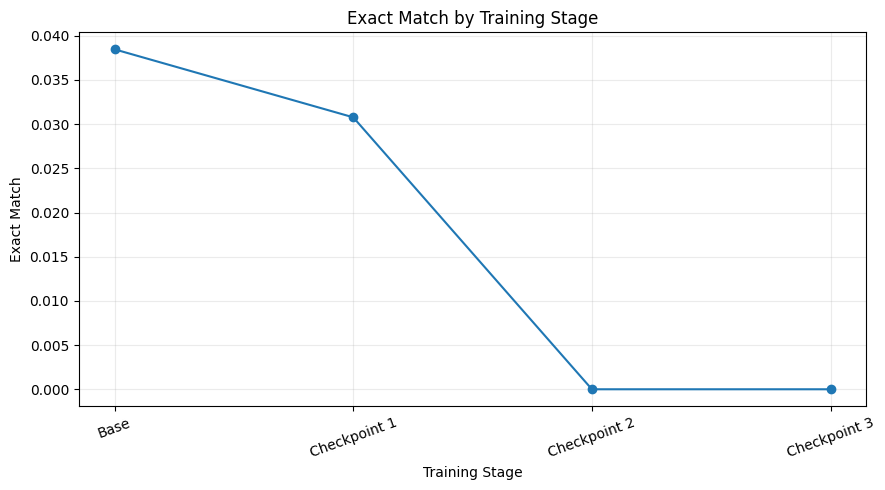

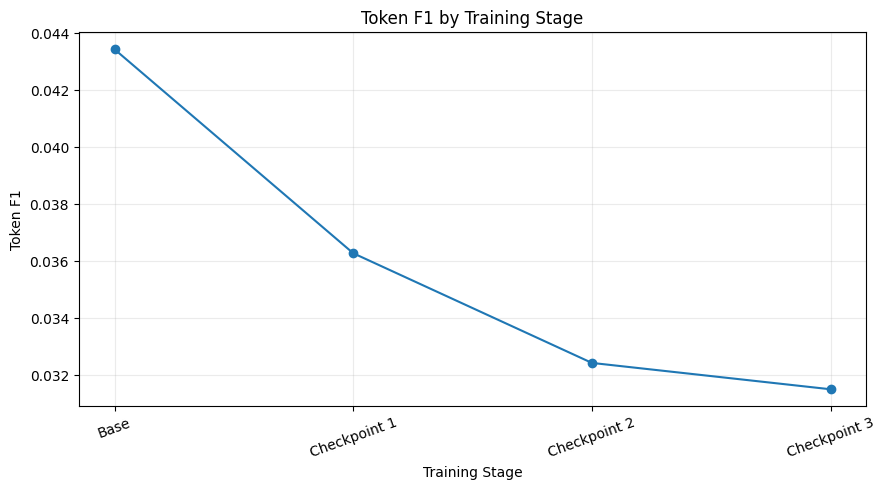

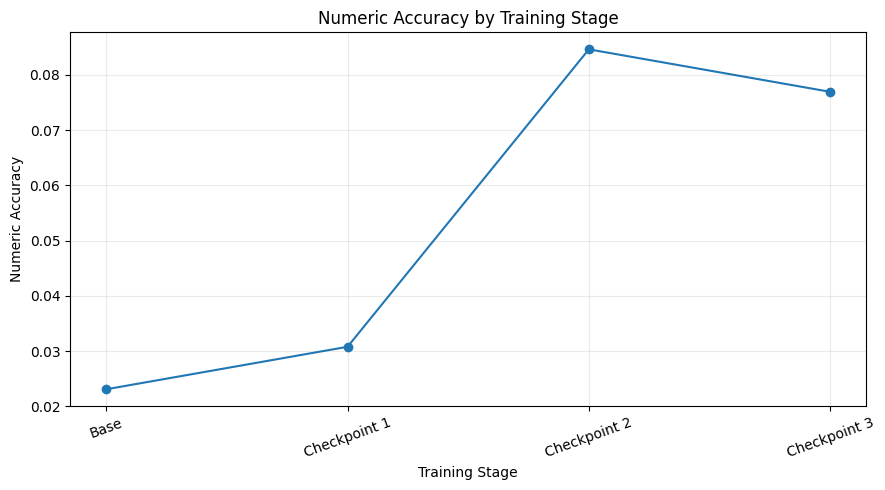

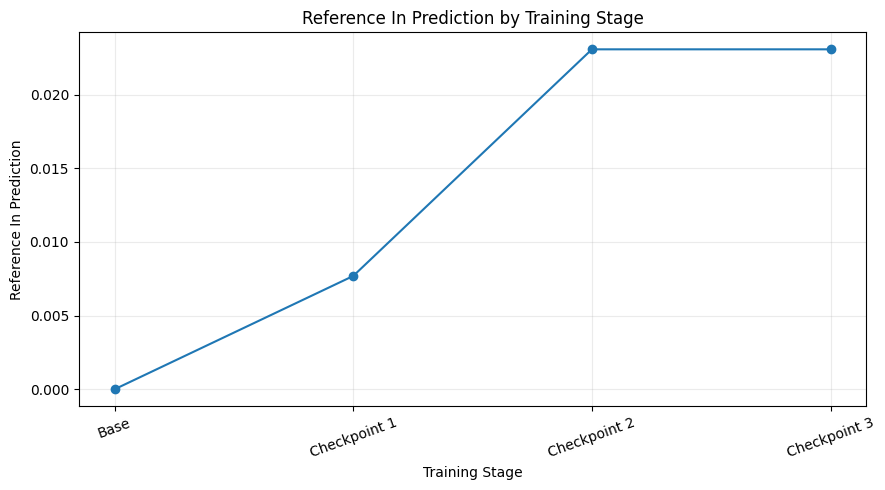

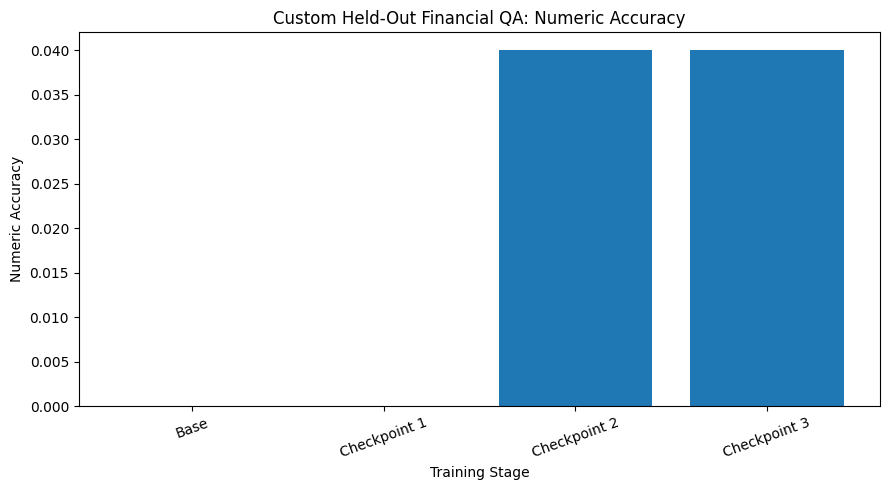

In [40]:
for metric in ["exact_match","token_f1","numeric_accuracy","reference_in_prediction"]:
    plt.figure(figsize=(9,5)); plt.plot(STAGES,overall[metric].values,marker="o")
    plt.title(metric.replace("_"," ").title()+" by Training Stage")
    plt.xlabel("Training Stage"); plt.ylabel(metric.replace("_"," ").title()); plt.xticks(rotation=20); plt.grid(alpha=.25); plt.tight_layout(); plt.show()

plt.figure(figsize=(9,5)); plt.bar(custom_summary.index,custom_summary["numeric_accuracy"].values)
plt.title("Custom Held-Out Financial QA: Numeric Accuracy"); plt.xlabel("Training Stage"); plt.ylabel("Numeric Accuracy"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()


## 10. Qualitative comparison and error analysis

Surface cases where Checkpoint 3 has a numeric or reference match even though Exact Match is 0. This helps distinguish strict string mismatch from genuinely useful explanatory answers.

In [41]:
metric_lookup = combined_df.pivot_table(
    index=["dataset", "id"],
    columns="stage",
    values=["exact_match", "numeric_accuracy", "reference_in_prediction"],
    aggfunc="first",
)
metric_lookup.columns = [
    f"{a}_{b}" for a, b in metric_lookup.columns
]
metric_lookup = metric_lookup.reset_index()

question_lookup = all_eval_df[
    ["dataset", "id", "question", "reference_answer"]
].drop_duplicates()

answers = combined_df.pivot_table(
    index=["dataset", "id"],
    columns="stage",
    values="prediction",
    aggfunc="first",
).reset_index()

examples = (
    metric_lookup
    .merge(question_lookup, on=["dataset", "id"], how="left")
    .merge(answers, on=["dataset", "id"], how="left")
)

c3_em = examples.get(
    "exact_match_Checkpoint 3",
    pd.Series(0, index=examples.index)
)
c3_num = examples.get(
    "numeric_accuracy_Checkpoint 3",
    pd.Series(0, index=examples.index)
)
c3_ref = examples.get(
    "reference_in_prediction_Checkpoint 3",
    pd.Series(0, index=examples.index)
)

useful = examples[
    (c3_em == 0) & ((c3_num == 1) | (c3_ref == 1))
].head(10)

display(useful[
    [
        "dataset", "id", "question", "reference_answer",
        "Checkpoint 3",
        "exact_match_Checkpoint 3",
        "numeric_accuracy_Checkpoint 3",
        "reference_in_prediction_Checkpoint 3",
    ]
])

,dataset,id,question,reference_answer,Checkpoint 3,exact_match_Checkpoint 3,numeric_accuracy_Checkpoint 3,reference_in_prediction_Checkpoint 3
7,ConvFinQA,Single_ETR/2008/page_355.pdf-4,and how much does this change represent in rel...,0.0814,the change in the number of gas customers from...,0,1,0
24,Custom-50,custom_fin_005,Which segment generated more revenue in Q2 202...,Solar projects,"Solar projects generated $0.51B in revenue, wh...",0,0,1
26,Custom-50,custom_fin_007,What was Aurora Grid's net income margin in Q2...,Approximately 10.1%,"Net income margin was 10.4% in Q2 2026, up fro...",0,1,0
32,Custom-50,custom_fin_013,What was the year-over-year growth rate in gro...,Approximately 12.4%,"The 2025 gross written premium was $11.4B, up ...",0,1,0
68,Custom-50,custom_fin_049,Did Vertex's software and recurring services r...,Yes,Yes. Software and recurring services revenue g...,0,0,1
94,FinQA,AWK/2012/page_117.pdf-4,what percentage of the company's gross liabili...,41.1%,The company's other long-term liabilities tota...,0,1,0
103,FinQA,L/2009/page_84.pdf-1,what was the growth rate of the loews common s...,60.6%,The growth rate was 60.62% from 2004 to 2009.,0,1,0
104,FinQA,LKQ/2016/page_87.pdf-4,in 2016 what was the percent of the total futu...,11.5%,The table shows that $ 136.5 million of the to...,0,1,1
109,FinQA,UNP/2006/page_15.pdf-2,"as of december 31 , 2006 what was the percent ...",53%,The 2006 annual report shows 27318 main line r...,0,1,0


## 11. Save the final benchmark report

Save automated metrics, custom held-out results, sanity status, optional judge results, and a human-readable Markdown report.

In [42]:
overall.to_csv(RESULTS_DIR / "overall_benchmark_summary.csv")
summary.to_csv(RESULTS_DIR / "dataset_level_benchmark_summary.csv", index=False)
custom_summary.to_csv(RESULTS_DIR / "custom_50_summary.csv")

report = {
    "project": "FinSight AI",
    "base_model": BASE_MODEL,
    "checkpoints": {
        "checkpoint_1": str(CHECKPOINT_1_ADAPTER),
        "checkpoint_2": str(CHECKPOINT_2_ADAPTER),
        "checkpoint_3": str(CHECKPOINT_3_ADAPTER),
    },
    "checkpoint_composition": {
        "Base": "Base model",
        "Checkpoint 1": "Base + Checkpoint 1 adapter",
        "Checkpoint 2": "Base + Checkpoint 2 adapter snapshot",
        "Checkpoint 3": "Base + Checkpoint 3 adapter snapshot",
        "note": (
            "C2 and C3 are successive adapter snapshots created by continued "
            "training in Notebook 3; they are not independent adapters to stack."
        ),
    },
    "evaluation_config": {
        "run_full_benchmarks": RUN_FULL_BENCHMARKS,
        "max_per_benchmark": MAX_PER_BENCHMARK,
        "custom_eval_full": CUSTOM_EVAL_FULL,
        "max_new_tokens": MAX_NEW_TOKENS,
        "temperature": TEMPERATURE,
        "do_sample": DO_SAMPLE,
        "seed": SEED,
        "prompt_mode": "mistral_chat_template",
    },
    "sanity_status": sanity_status,
    "overall_metrics": overall.round(6).to_dict(),
    "custom_50_metrics": custom_summary.round(6).to_dict(),
    "llm_judge": {
        "enabled": bool(len(judge_results)),
        "model": JUDGE_MODEL if len(judge_results) else None,
        "samples_per_stage": JUDGE_SAMPLES_PER_STAGE if len(judge_results) else 0,
        "summary": judge_summary.round(6).to_dict() if len(judge_results) else {},
    },
}

(RESULTS_DIR / "final_benchmark_report.json").write_text(
    json.dumps(report, indent=2, default=str),
    encoding="utf-8",
)

lines = [
    "# FinSight AI - Final Evaluation Report",
    "",
    f"**Base model:** `{BASE_MODEL}`",
    "",
    "## Overall automated metrics",
    "",
    overall.round(4).reset_index().to_markdown(index=False),
    "",
    "## Custom 50 held-out results",
    "",
    custom_summary.round(4).reset_index().to_markdown(index=False),
    "",
    "## Sanity-test status",
    "",
]
for stage, ok in sanity_status.items():
    lines.append(f"- **{stage}:** {'PASS' if ok else 'FAIL'}")

if len(judge_results):
    lines += [
        "",
        "## LLM-as-a-Judge",
        "",
        f"Judge model: `{JUDGE_MODEL}`",
        "",
        judge_summary.round(3).reset_index().to_markdown(index=False),
    ]
else:
    lines += [
        "",
        "## LLM-as-a-Judge",
        "",
        "Not run because OPENAI_API_KEY was unavailable or judging was disabled.",
    ]

lines += [
    "",
    "## Interpretation note",
    "",
    "Exact Match is strict for explanatory financial answers. Numeric matching and "
    "reference-in-prediction are complementary diagnostics. The LLM-as-a-Judge "
    "sample is small and should support, not replace, human evaluation.",
]

(RESULTS_DIR / "final_benchmark_report.md").write_text(
    "\n".join(lines),
    encoding="utf-8",
)

print("Final report files saved to:", RESULTS_DIR)

Final report files saved to: /content/FinSight_evaluation_results


## 12. Portfolio interpretation

Describe the progression **Base → DAPT C1 → SFT C2 → DPO C3** using the combined evidence.

Recommended structure:
1. DAPT impact on external financial QA.
2. SFT impact on numerical correctness, reference coverage, and judged correctness.
3. DPO impact on groundedness, numerical correctness, completeness, and hallucination behavior.
4. Limitations of Exact Match and numeric-match metrics.
5. Limitations of the small LLM-as-a-Judge sample.

Do not claim universal superiority from a small evaluation sample. Report the measured changes and their limitations.